# Experiment 4
## Electricity demand forecasting
### Real data

In [48]:
import sys, os
sys.path.append(os.path.abspath(".."))

from src.imports import *
from src.simulation import consumption_simulate
from src.ridge_signatures import ridge_signatures
from src.baselines import run_baselines_real
from src.utils import setup_latex_plotting, exponential_smoothing

### Load data

In [49]:
base_dir = Path.cwd().parent
file_path = base_dir / "data" / "data.csv"

df = pd.read_csv(file_path, decimal=".")
df["DateTime"] = pd.to_datetime(df["DateTime"])
temp = np.array(df["Temperature"])
consumption = np.array(df["Consumption"])
dates = df["DateTime"]

### Fit RidgeSig on data and calculate error metrics

In [50]:
# Set parameters and define dictionaries 

delay_days = 7
delay = delay_days*48
n_windows = 31
windows_days = np.array(range(delay_days, n_windows + delay_days))
windows = [48 * i for i in windows_days]
trunc_orders = [3, 4, 5, 6]
lambdas = np.logspace(-1, 2, 20)
n_train = (df["DateTime"] < "2014-01-01 00:00:00").sum()
n_valid = ((df["DateTime"] >= "2014-01-01 00:00:00") & 
           (df["DateTime"] <  "2015-01-01 00:00:00")).sum()
alpha1 = 0.005

METRICS = {
    "rmse": root_mean_squared_error,
    "mae": mean_absolute_error,
    "mape": mean_absolute_percentage_error,
}

models = {
    rf"$\overline{{T}}, {{\overline{{T}}}}^2": "baseline1",
    rf"$T, T^2, \overline{{T}}, {{\overline{{T}}}}^2$": "baseline2",
    rf"$\left(T, T^2, \overline{{T}}, \overline{{T}}^2, Y_{{t-7\text{{ days}}}} \right)$": "baseline3"
}

errors_sig = {
    d: {m: np.empty(len(windows)) for m in METRICS.keys()}
    for d in trunc_orders
}

metrics = ("rmse", "mae", "mape")


# Fit RidgeSig and calculate error metrics 

for j, d in enumerate(trunc_orders):
    for k, w in enumerate(windows):
        for m in metrics: 
            result = ridge_signatures(
                covariates=temp,
                target=consumption,
                window=w,
                delay=48 * delay_days,
                n_train=n_train,
                n_valid=n_valid,
                trunc_order=d,
                penalties=lambdas,
                tune_penalty=True,
                metric=m,  
            )
            
            errors_sig[d][m][k] = result["error_test"]
    

### Fit baseline models and compare

In [51]:
errors = []
windows_days = np.array(range(delay_days, n_windows + delay_days))
base_results = run_baselines_real(temp, consumption, n_train+n_valid, alpha1, delay_days)

# Baseline models
for label, key in models.items():
    row = {"model": label}
    for m_name in METRICS.keys():
        row[m_name] = base_results[key]["metrics_test"][m_name]
    errors.append(row)

# Naive lag model (Y_{t-7 days})
row = {"model": r"$Y_{t-\text{7 days}}$"}
for m_name, m_func in METRICS.items():
    row[m_name] = m_func(
        consumption[n_train:],
        consumption[n_train - delay_days * 48 : -delay_days * 48]
    )
errors.append(row)

# Ridge regression on signatures (minimum across windows, per metric and depth)
for d in trunc_orders:
    row = {"model": f"Ridge regression (depth={d})"}
    for m_name in METRICS.keys():
        row[m_name] = errors_sig[d][m_name].min()
    errors.append(row)

results_df = pd.DataFrame(errors)
print(tabulate(results_df, headers='keys', tablefmt='grid', showindex=False))


+---------------------------------------------------------------------------+---------+---------+-----------+
| model                                                                     |    rmse |     mae |      mape |
+===========================================================================+=========+=========+===========+
| $\overline{T}, {\overline{T}}^2                                           | 6518.42 | 5449.81 | 0.106742  |
+---------------------------------------------------------------------------+---------+---------+-----------+
| $T, T^2, \overline{T}, {\overline{T}}^2$                                  | 6171.63 | 5103.35 | 0.0988179 |
+---------------------------------------------------------------------------+---------+---------+-----------+
| $\left(T, T^2, \overline{T}, \overline{T}^2, Y_{t-7\text{ days}} \right)$ | 3733.38 | 2822.1  | 0.0528506 |
+---------------------------------------------------------------------------+---------+---------+-----------+
| $Y_{t-\t

### Compare predictions from best RidgeSig and baseline model

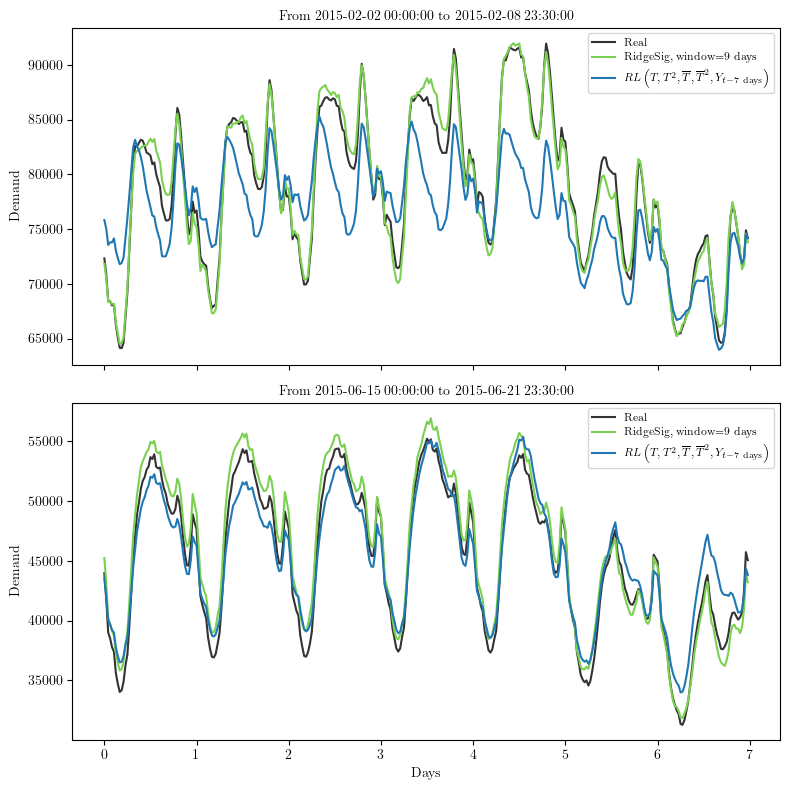

In [52]:
# Parameters
delay_days = 7
delay = delay_days*48
window_days = 9
window = window_days*48
trunc_order = 6
lambdas = np.logspace(-1, 2, 20)
n_train = (df["DateTime"] < "2014-01-01 00:00:00").sum()
n_valid = ((df["DateTime"] >= "2014-01-01 00:00:00") & 
           (df["DateTime"] <  "2015-01-01 00:00:00")).sum()
metric = "rmse"

# Obtain predictions for the best performing RidgeSig model (best window size)
result = ridge_signatures(
    covariates=temp,
    target=consumption,
    window=window,
    delay=48 * delay_days,
    n_train=n_train,
    n_valid=n_valid,
    trunc_order=trunc_order,
    penalties=lambdas,
    tune_penalty=True,
    metric=metric,  
)
       
y_pred_sig = result["y_pred_test"]


# Refit the best baseline so dates are aligned
alpha1 = 0.005
temp_smooth1 = exponential_smoothing(temp, smooth_param=alpha1)
datetime = df["DateTime"]

df_reg = pd.DataFrame({
    "Temperature": temp,
    "Temp_sq": temp**2,
    "Temp_smooth1": temp_smooth1,
    "Temp_smooth1_sq": temp_smooth1**2,
    "Consumption": consumption
})

df_reg["Consumption_delay"] = df_reg["Consumption"].shift(delay)
df_model = df_reg.dropna().reset_index(drop=True)
X = df_model[["Temperature", "Temp_sq", "Temp_smooth1", "Temp_smooth1_sq", "Consumption_delay"]]
y = df_model["Consumption"]

X_train, X_test = X.iloc[window:n_train+n_valid+window], X.iloc[n_train+n_valid+window:]
y_train, y_test = y.iloc[window:n_train+n_valid+window], y.iloc[n_train+n_valid+window:]

lr = LinearRegression()
lr.fit(X_train, y_train)

y_pred_baseline = lr.predict(X_test)

# Align dates
dates_train_valid = dates[window:n_train + n_valid + window]
dates_test  = dates[n_train + n_valid + window:]
consumption_train = consumption[window:n_train + n_valid + window]
consumption_test  = consumption[n_train + n_valid + window:]

# Plot
setup_latex_plotting()
fig, axes = plt.subplots(2, 1, figsize=(8, 8), sharex=True)


# First plot - winter week

mask = (dates_test >= start) & (dates_test <= end)
mask_indices = np.where(mask)[0]  

n_points = len(consumption_test[mask_indices])
day_ticks = np.arange(0, n_points+1, 48)
day_labels = np.arange(0, len(day_ticks))  # 0, 1, 2, ...

axes[0].plot(consumption_test[mask_indices], label="Real", color="#333333")
axes[0].plot(y_pred_sig[mask_indices], label=f"RidgeSig, window={window_days} days",color="#7AD151")
axes[0].plot(
    y_pred_baseline[mask_indices],
    label=rf"$RL\left(T, T^2, \overline{{T}}, \overline{{T}}^2, Y_{{t-7\text{{ days}}}} \right)$",
    color="#1f77b4"
)
axes[0].set_ylabel("Demand",fontsize=10)
axes[0].set_title(f"From {start} to {end}", fontsize=10)
axes[0].legend(loc="upper right", fontsize=8)
axes[0].tick_params(labelbottom=False)  


#  Second plot - summer week

start_summer = "2015-06-15 00:00:00"
end_summer   = "2015-06-21 23:30:00"
mask_summer = (dates_test >= start_summer) & (dates_test <= end_summer)
mask_summer_indices = np.where(mask_summer)[0]

axes[1].plot(consumption_test[mask_summer_indices], label="Real",color="#333333")
axes[1].plot(y_pred_sig[mask_summer_indices], label=f"RidgeSig, window={window_days} days",color="#7AD151")
axes[1].plot(
    y_pred_baseline[mask_summer_indices],
    label=rf"$RL\left(T, T^2, \overline{{T}}, \overline{{T}}^2, Y_{{t-7\text{{ days}}}} \right)$",
    color="#1f77b4"
)
axes[1].set_ylabel("Demand",fontsize=10)
axes[1].set_title(f"From {start_summer} to {end_summer}", fontsize=10)
axes[1].set_xlabel("Days",fontsize=10)
axes[1].set_xticks(day_ticks)
axes[1].set_xticklabels(day_labels)
axes[1].legend(loc="upper right", fontsize=8)

plt.tight_layout()
plt.show()
